# 1 — Processing data


## Imports


In [15]:
from pathlib import Path
import hashlib
import json
from collections import Counter
import numpy as np
import pandas as pd
import wfdb
import matplotlib.pyplot as plt
from IPython.display import display


## Configuration


In [16]:
from pathlib import Path
# ใช้ project root เดียวกัน ไม่ต้อง import โค้ด pipeline จาก program
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'dataset').is_dir() and (p / 'model').is_dir() and (p / 'program').is_dir())
RAW = ROOT / 'dataset/raw/mit-bih-arrhythmia-database-1.0.0'
DATA = ROOT / 'dataset/processed'
ARTIFACTS = ROOT / 'model/artifacts'
REPORTS = ROOT / 'model/reports'
CLASSES = ['N', 'S', 'V', 'F', 'Q']
SYMBOLS = ['NLRej', 'AaJS', 'VE', 'F', '/fQ']
LABEL_MAP = {s: i for i, group in enumerate(SYMBOLS) for s in group}
SEED = 42
PREPROCESSING = {'version': 1, 'fs': 360, 'left': 90, 'right': 162,
                 'band': [0.5, 40], 'order': 4, 'leads': ['MLII', 'V5']}

## Artifact helpers


In [17]:
def read_json(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'ไม่พบ {path}; กรุณารัน notebook ขั้นก่อนหน้าก่อน')
    return json.loads(path.read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def new_stage(marker):
    # ห้ามเขียนทับผลเดิมเงียบ ๆ เพราะอาจทำให้โมเดลอ้างอิงคนละ split
    if Path(marker).exists():
        raise FileExistsError(f'มีผลขั้นนี้แล้ว: {marker}; โหลดผลเดิมแทนการรันซ้ำ')
    if (ARTIFACTS / 'selection.json').exists():
        raise RuntimeError('ล็อกโมเดลแล้ว ไม่อนุญาตให้เตรียมข้อมูลหรือ tuning ใหม่ใน experiment เดิม')

## Read ECG and choose lead


In [18]:
def choose_lead(names):
    for name in PREPROCESSING['leads']:
        if name in names:
            return names.index(name), name
    raise ValueError(f'ไม่มี lead MLII หรือ V5: {names}')

def read_record(path):
    record = wfdb.rdrecord(str(path))
    if record.fs != PREPROCESSING['fs']:
        raise ValueError(f'ต้องการ 360 Hz แต่พบ {record.fs}')
    index, lead = choose_lead(record.sig_name)
    signal = np.asarray(record.p_signal[:, index], dtype=np.float64)
    if len(signal) != record.sig_len or not np.isfinite(signal).all():
        # ไม่ filter ข้าม NaN เพราะจะกระจายความเสียหายไปทั้ง record
        raise ValueError(f'{path}: signal ไม่ครบหรือมี NaN/Inf ต้องตรวจสอบก่อน')
    return signal, lead

## Load records


In [19]:
raw = RAW
new_stage(DATA / 'audit.json')
records_file = raw / 'RECORDS'
if not records_file.exists():
    raise FileNotFoundError(f'วาง MIT-BIH พร้อม RECORDS ที่ {raw}')
records = records_file.read_text().split()
if len(records) != 48 or len(set(records)) != 48 or not all(r.isdigit() for r in records):
    raise ValueError('ต้องใช้ 48 records หลักจาก RECORDS เท่านั้น')
DATA.mkdir(parents=True, exist_ok=True)
rows, inventory, excluded, checksums = [], [], [], {}
nonbeats = set('~+[]!"|x()p t u `\'sT=^@')

## Audit and map labels


In [20]:
for record_id in records:
    for ext in ['hea', 'dat', 'atr']:
        path = raw / f'{record_id}.{ext}'
        checksums[path.name] = sha256(path)
    signal, lead = read_record(raw / record_id)
    ann = wfdb.rdann(str(raw / record_id), 'atr')
    if np.any(ann.sample < 0) or np.any(ann.sample >= len(signal)):
        raise ValueError(f'{record_id}: annotation bounds ไม่ถูกต้อง')
    patient = '201_202' if record_id in ['201', '202'] else record_id
    counts = Counter(ann.symbol)
    for r, symbol in zip(ann.sample, ann.symbol):
        if symbol not in LABEL_MAP:
            excluded.append({'record_id': record_id, 'r_sample': int(r), 'symbol': symbol,
                             'reason': 'non_beat' if symbol in nonbeats else 'unmapped_review'})
            continue
        rows.append({'beat_id': f'{record_id}:{r}', 'record_id': record_id,
                     'patient_group': patient, 'r_sample': int(r),
                     'original_symbol': symbol, 'class_id': LABEL_MAP[symbol], 'lead': lead})
    inventory.append({'record_id': record_id, 'patient_group': patient,
                      'lead': lead, 'samples': len(signal), 'symbol_counts': dict(counts)})

## Validate and save inventory


In [21]:
beats = pd.DataFrame(rows)
if beats.beat_id.duplicated().any():
    raise ValueError('beat_id ซ้ำ ต้องตรวจ annotations')
beats.to_parquet(DATA / 'inventory.parquet', index=False)
pd.DataFrame(excluded, columns=['record_id', 'r_sample', 'symbol', 'reason']).to_csv(
    DATA / 'excluded_annotations.csv', index=False)
beats.groupby(['patient_group', 'class_id']).size().unstack(fill_value=0).to_csv(
    DATA / 'patient_class_counts.csv')
result = {'dataset_version': 'mit-bih-arrhythmia-database-1.0.0', 'files': checksums,
          'records': inventory, 'excluded_symbols': dict(Counter(x['symbol'] for x in excluded)),
          'unmapped_symbols': sorted({x['symbol'] for x in excluded if x['reason'] == 'unmapped_review'})}
write_json(DATA / 'audit.json', result)
beats

,beat_id,record_id,patient_group,r_sample,original_symbol,class_id,lead
0,100:77,100,100,77,N,0,MLII
1,100:370,100,100,370,N,0,MLII
2,100:662,100,100,662,N,0,MLII
3,100:946,100,100,946,N,0,MLII
4,100:1231,100,100,1231,N,0,MLII
...,...,...,...,...,...,...,...
109489,234:648797,234,234,648797,N,0,MLII
109490,234:649040,234,234,649040,N,0,MLII
109491,234:649292,234,234,649292,N,0,MLII
109492,234:649536,234,234,649536,N,0,MLII


## Class distribution

Summarize all mapped beats before splitting or preprocessing. Counts exclude non-beat and unmapped annotations. If `beats` is unavailable in the current kernel, load the saved patient counts from the processing stage.


In [22]:
# Keep all five classes in the configured order, including classes with zero beats.
if 'beats' in globals():
    class_counts = beats['class_id'].value_counts().reindex(range(len(CLASSES)), fill_value=0)
else:
    patient_counts = pd.read_csv(DATA / 'patient_class_counts.csv', index_col=0)
    class_counts = patient_counts.reindex(
        columns=[str(i) for i in range(len(CLASSES))], fill_value=0
    ).sum(axis=0)

total_beats = int(class_counts.sum())
class_summary = pd.DataFrame({
    'Class': CLASSES,
    'Count': class_counts.to_numpy(dtype=int),
})
class_summary['Percentage (%)'] = (
    class_summary['Count'] / total_beats * 100 if total_beats else 0.0
)
display(class_summary.style.format({'Count': '{:,}', 'Percentage (%)': '{:.2f}'}).hide(axis='index'))
print(f'Total mapped beats: {total_beats:,}')


Class,Count,Percentage (%)
N,"90,631",82.77
S,"2,781",2.54
V,"7,236",6.61
F,803,0.73
Q,"8,043",7.35


Total mapped beats: 109,494


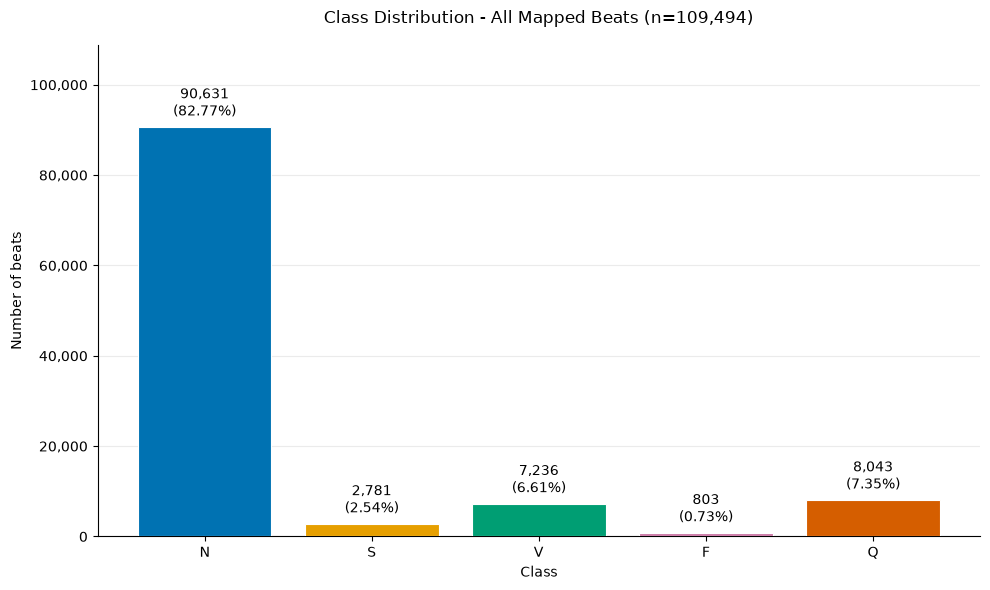

In [23]:
# A fixed color for each class makes the distribution easy to compare.
class_colors = {'N': '#0072B2', 'S': '#E69F00', 'V': '#009E73',
                'F': '#CC79A7', 'Q': '#D55E00'}
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    class_summary['Class'], class_summary['Count'],
    color=[class_colors[label] for label in class_summary['Class']],
    edgecolor='white', linewidth=0.8, zorder=3,
)
ax.bar_label(bars, labels=[
    f'{count:,}\n({percentage:.2f}%)'
    for count, percentage in zip(class_summary['Count'], class_summary['Percentage (%)'])
], padding=5, fontsize=10)
ax.set_title(f'Class Distribution - All Mapped Beats (n={total_beats:,})', pad=16)
ax.set_xlabel('Class')
ax.set_ylabel('Number of beats')
ax.set_ylim(0, max(class_summary['Count'].max() * 1.2, 1))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax.grid(axis='y', alpha=0.25, zorder=0)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()
